# Estado del arte: ajuste de curvas, tasas estocásticas, modelos de depósitos, la recalibración de 2024 y la brecha de código abierto

**Pregunta:** ¿cuánto importa qué método del estado del arte elige un validador para el IRRBB del banco que quebró en 2023: cuánto mueven su EVE y su NII la familia de curvas, las aproximaciones de primer orden, el tratamiento de los depósitos y la recalibración de 2024, dónde se detiene el motor, y alguna elección cambia el veredicto?

- **Nivel:** 3, Estado del arte
- **Requisitos previos:** los notebooks 01 a 06 de este tema
- **Tiempo de lectura:** unos 55 minutos

## Objetivos

Al terminar este notebook puedes:

- ubicar los métodos del caso (curvas Nelson-Siegel y Svensson, Nelson-Siegel dinámico, escenarios de Hull-White, la cartera replicante, el beta de depósitos, los modelos de prepago) en el estado del arte que encontró la investigación, con sus fuentes, y decir qué implementa el motor y qué no;
- medir cuánto mueve la elección de la familia de curvas el EVE del mismo balance;
- comparar las aproximaciones de primer orden de brecha y de duración con la revaluación completa y con el NII dinámico en las mismas tres fechas, y decir cuándo discrepan incluso en el signo;
- comparar tres tratamientos de los depósitos (todo depósito a un día, los topes del estándar y la cartera replicante interna) sobre los mismos flujos;
- leer lado a lado las calibraciones de 2016 y de 2024, y declarar qué se sabe de las herramientas de código abierto que podrían desafiar los resultados.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.irrbb import curves, eve_nii, shocks, slotting

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
matplotlib 3.11.2


## Datos

Los datos son el caso C14, el riesgo de tasa de interés en el libro de banca (IRRBB) del banco que quebró en marzo de 2023, en tres fechas de valoración, 2021-Q4, 2022-Q2 y 2022-Q4, tal como Contraste lo versiona: los reportes de condición de la FDIC (FDIC BankFind financials, https://api.fdic.gov/banks/financials) y la curva a la par del Tesoro de EE. UU. (https://home.treasury.gov/resource-center/data-chart-center/interest-rates), fuentes de dominio público de la clase de licencia `mirror-allowed`. El banco es **real en agregado y sintético en comportamiento**. El dinero está en miles de USD y un delta EVE positivo es una pérdida.

- **Archivos que se leen:** `data/derived/C14/vd-2021-q4.json`, `vd-2022-q2.json` y `vd-2022-q4.json` (`outputs.balance_sheet`, `curve`, `scenarios`, `behavioural_comparison`, `ladder`, `dynamic_nii`, `nmd_segments`) y `models-svb-2021-2022.json` (`fit.nmd_models`, los ajustes replicantes). Las notas de investigación detrás del estado del arte son los dossiers 01 (marco de Basilea), 03 (Chile) y 05 (modelos de mercado, ALM y liquidez) de la investigación de Contraste.

El notebook de nivel 3 compara, sobre los mismos datos, lo que hace el caso (niveles 1 y 2) con lo que ofrece la literatura. La celda siguiente carga los archivos y reconstruye, para cada fecha, los flujos netos del balance bajo el tratamiento conductual y el contractual (como en el notebook 01).

In [2]:
# Cargar las tres fechas y el documento de modelos; rearmar los flujos netos de cada tratamiento y las tasas cero
ROOT = Path("../../..").resolve()
derived = ROOT / "data" / "derived" / "C14"
quarters = ("2021-Q4", "2022-Q2", "2022-Q4")
docs = {q: json.loads((derived / f"vd-{q.lower()}.json").read_text(encoding="utf-8")) for q in quarters}
fit = json.loads((derived / "models-svb-2021-2022.json").read_text(encoding="utf-8"))["fit"]
MID = slotting.bucket_grid().midpoints
LANG = "es"  # los campos bilingües de los documentos se leen en este idioma
NAME = {"behavioural": "conductual", "contractual": "contractual"}
NAME.update({"parallel-up": "paralelo al alza", "parallel-down": "paralelo a la baja", "steepener": "empinamiento"})
NAME.update({"flattener": "aplanamiento", "short-up": "corto al alza", "short-down": "corto a la baja"})
book = {}
for q, d in docs.items():
    o = d["outputs"]
    sides = {}
    for treatment in ("behavioural", "contractual"):
        a, l = np.zeros(19), np.zeros(19)
        for item in o["balance_sheet"]["items"]:
            target, sign = (a, 1.0) if item["side"] == "asset" else (l, -1.0)
            for row in item["cash_flows"][treatment]:
                target[row["bucket"] - 1] += sign * row["amount"]
        sides[treatment] = (a, l)
    r0 = np.array(o["curve"]["zero_rates_at_midpoints"])
    book[q] = {"flows": sides, "r0": r0, "tier1": o["scenarios"][0]["outlier"]["tier1"]}
    print(q, o["valuation_date"], "| Tier 1", f"{book[q]['tier1']:,.0f}")

2021-Q4 2021-12-31 | Tier 1 14,622,000
2022-Q2 2022-06-30 | Tier 1 16,349,000
2022-Q4 2022-12-31 | Tier 1 16,995,000


## Método

Cada comparación siguiente usa los mismos flujos y curvas versionados que los notebooks de nivel 2 y cambia una elección a la vez, de modo que una diferencia en el resultado se pueda atribuir a esa elección. Hay cuatro comparaciones: (1) la familia de curvas, (2) las aproximaciones de primer orden contra la revaluación completa y la proyección dinámica, (3) tres tratamientos de los depósitos, y (4) las calibraciones de 2016 y de 2024. Las cuatro corren el motor sobre los flujos y curvas versionados. Cada una se presenta con el estado del arte que representa, en la sección siguiente.

## Estado del arte

La investigación (dossier 05, D.1 a D.7, y dossier 01, H) encontró las siguientes familias para cada parte de la medición de IRRBB. La columna derecha dice qué implementa el motor `riskvalidation` 1.0.1 y qué no, según su código en la etiqueta.

| Parte | Estado del arte (fuente) | En el motor |
|---|---|---|
| Ajuste de curvas | Nelson y Siegel (1987, https://doi.org/10.1086/296409); Svensson (1994, https://doi.org/10.3386/w4871); Nelson-Siegel dinámico, Diebold y Li (2006, https://doi.org/10.1016/j.jeconom.2005.03.005) | `fit_nelson_siegel`, `fit_svensson`, `fit_dns_factors`, `forecast_dns_factors`; el decaimiento 0,0609 por mes es una constante |
| Interpolación | Hagan y West (2006, https://doi.org/10.1080/13504860500396032): la convexa monótona y otros esquemas cambian los plazos de forma material | lineal en el plazo, plana fuera de la grilla (`zero_rates_at`); ningún otro esquema |
| Escenarios de tasa corta | Vasicek (1977, https://doi.org/10.1016/0304-405X(77)90016-2); Hull y White (1990, https://doi.org/10.1093/rfs/3.4.573) | `hw1f_scenarios` (Hull-White de un factor, antitético); sin Vasicek |
| Depósitos a la vista | cartera replicante estática (BCBS d368, nota 38); valoración por derechos contingentes, Jarrow y van Deventer (1998, https://doi.org/10.1016/S0378-4266(97)00058-7); modelo de tres factores, Kalkbrener y Willing (2004, https://doi.org/10.1016/S0378-4266(03)00131-6); programación estocástica, Frauendorfer y Schurle (2003, https://doi.org/10.1016/S0377-2217(02)00626-4) | `replicating_portfolio` (estática, exacta hasta 10 tramos); ninguno de los otros tres |
| Beta de depósitos | traspaso asimétrico, Drechsler, Savov y Schnabl (2021, https://doi.org/10.1111/jofi.13013) | `deposit_beta_passthrough` (betas al alza y a la baja); el ajuste es del proceso del producto |
| Prepago | SMM, CPR y PSA, Fuster, Lucca y Vickery (2022); ejercicio racional, Stanton (1995, https://doi.org/10.1093/rfs/8.3.677); riesgos proporcionales, Schwartz y Torous (1989, https://doi.org/10.1111/j.1540-6261.1989.tb05062.x); riesgos competitivos, Deng, Quigley y Van Order (2000, https://doi.org/10.1111/1468-0262.00110) | `smm_from_cpr`, `cpr_from_smm`, `psa_cpr`, `prepayment_logit` y `fit_prepayment_logit` (un logit sobre incentivo y antigüedad; sin agotamiento ni estacionalidad) |
| Tamaños de choque | BCBS d368 (2016) y la recalibración d578 (2024, vigente desde 2026-01-01): percentil 99,9 de cambios de seis meses, 2000 a 2023, redondeado a 25 pb | ambas tablas como fixtures (`shock_table`); la de 2016 está verificada con una salvedad de la capa de texto, la de 2024 es la Tabla 2 de SRP31.90 |
| La lección del banco quebrado | la revisión de la Reserva Federal encontró que el banco hizo supuestos contraintuitivos sobre la duración de los depósitos para enfrentar un exceso (https://www.federalreserve.gov/publications/files/svb-review-20230428.pdf) | `eve_with_without_behavioural` y `behavioural_change_at_breach` (notebooks 05 y 08) |
| Motores de código abierto | la investigación no encontró un motor ALM o IRRBB de código abierto maduro; ORE y QuantLib cubren curvas, Hull-White y exposición, no el balance de un banco (dossier 05, D.6 e I.3) | no aplica; la ausencia es un hallazgo de la búsqueda del dossier, **NO VERIFICADA** más allá de ella |

Dos cautelas sobre la tabla. La investigación anota que los valores de 2024 no se obtuvieron en el dossier de mercado (dossier 05, D.2: "NO VERIFICADO") y están transcritos en el dossier de Basilea (dossier 01, H.3); el motor toma el segundo. Y el decaimiento de Diebold-Li se declara en el artículo como el que maximiza la carga de curvatura a los 30 meses; el motor documenta 29,446 meses (notebook 04).

### Comparación 1: la familia de curvas

Hagan y West (2006) muestran que el esquema de interpolación mueve de forma material las tasas a plazo; la familia ajustada a la curva de mercado hace lo mismo con los valores presentes. La celda compara cuatro maneras de obtener las 19 tasas cero de cada fecha desde los mismos 12 rendimientos observados: la del proceso del producto (construcción e interpolación lineal), el ajuste Nelson-Siegel, el ajuste Svensson y las cargas del Nelson-Siegel dinámico con el decaimiento fijo. Para cada una la celda recalcula el EVE de los flujos netos conductuales e imprime la diferencia contra la del proceso, en dinero y como proporción del Tier 1, y la mayor brecha en las tasas.

curva | EVE | diferencia | proporción del Tier 1 | mayor brecha de tasa (pb)
2021-Q4 proceso: construcción + lineal        8,982,670          0   0.0000    0.0
2021-Q4 Nelson-Siegel                         8,813,494   -169,176  -0.0116   10.2
2021-Q4 Svensson                              8,961,548    -21,122  -0.0014   24.0
2021-Q4 Nelson-Siegel dinámico (λ fijo)       8,841,860   -140,810  -0.0096   11.7
2022-Q2 proceso: construcción + lineal        7,036,780          0   0.0000    0.0
2022-Q2 Nelson-Siegel                         7,142,430    105,650   0.0065   46.3
2022-Q2 Svensson                              6,647,794   -388,987  -0.0238   31.0
2022-Q2 Nelson-Siegel dinámico (λ fijo)       7,360,948    324,168   0.0198   37.4
2022-Q4 proceso: construcción + lineal        5,257,968          0   0.0000    0.0
2022-Q4 Nelson-Siegel                         5,284,342     26,374   0.0016   52.3
2022-Q4 Svensson                              4,996,362   -261,606  -0.0154   15.4
2022-Q4 Ne

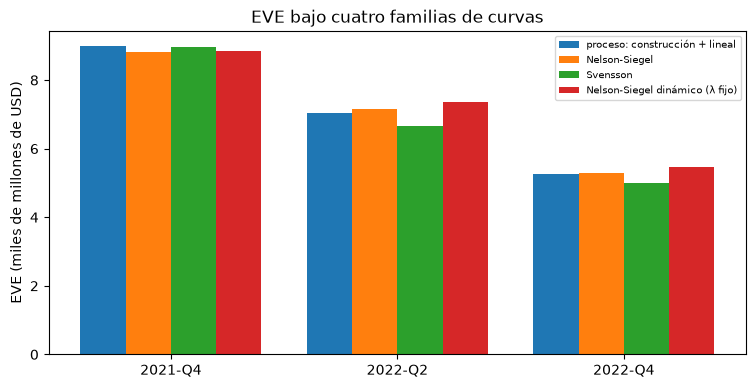

In [3]:
# EVE de los flujos conductuales con cuatro maneras de obtener las tasas cero, contra la curva interpolada del proceso
families = {}
print("curva | EVE | diferencia | proporción del Tier 1 | mayor brecha de tasa (pb)")
for q, d in docs.items():
    pts = d["outputs"]["curve"]["points"]
    tenors = np.array([p["tenor_years"] for p in pts])
    zero = np.array([p["zero_rate"] for p in pts])
    ns = curves.fit_nelson_siegel(tenors, zero)
    sv = curves.fit_svensson(tenors, zero)
    factors = curves.fit_dns_factors(tenors * 12.0, zero[None, :])[0]
    rates = {"proceso: construcción + lineal": book[q]["r0"]}
    rates["Nelson-Siegel"] = curves.nelson_siegel_yield(MID, ns.beta0, ns.beta1, ns.beta2, ns.tau)
    rates["Svensson"] = curves.svensson_yield(MID, sv.beta0, sv.beta1, sv.beta2, sv.beta3, sv.tau1, sv.tau2)
    rates["Nelson-Siegel dinámico (λ fijo)"] = curves.dns_yield(MID * 12.0, *factors)
    a, l = book[q]["flows"]["behavioural"]
    for name, r in rates.items():
        families[(q, name)] = eve_nii.eve(a - l, r, MID)
        diff = families[(q, name)] - families[(q, "proceso: construcción + lineal")]
        gap = np.abs(r - book[q]["r0"]).max() * 1e4
        print(f"{q} {name:34s} {families[(q, name)]:12,.0f} {diff:10,.0f} {diff / book[q]['tier1']:8.4f} {gap:6.1f}")
fig, ax = plt.subplots(figsize=(9, 4.2))
names = list(dict.fromkeys(n for _, n in families))
for k, name in enumerate(names):
    ax.bar(np.arange(3) + k * 0.2 - 0.3, [families[(q, name)] / 1e6 for q in docs], 0.2, label=name)
ax.set_xticks(range(3), list(docs))
ax.set_ylabel("EVE (miles de millones de USD)")
ax.set_title("EVE bajo cuatro familias de curvas")
ax.legend(fontsize=7)
plt.show()

Las cuatro barras de cada fecha están cerca pero no son iguales. En 2022-Q2 el EVE va de 6.647.794 con Svensson a 7.360.948 con las cargas del Nelson-Siegel dinámico, en torno a los 7.036.780 de la curva del proceso: una dispersión de 713.154, que es 4,4 por ciento del Tier 1 y 10 por ciento del propio EVE, y la mayor brecha en una sola tasa llega a 52,3 pb en 2022-Q4. La curva del proceso pasa por todos los puntos observados y las familias ajustadas los suavizan, con errores de 10 y 13 pb, así que la comparación dice cuán sensible es el resultado a la elección de la familia, no cuál curva es la correcta. La medida de Basilea es una razón al Tier 1, así que la elección no cambia aquí un veredicto, pero es una dispersión que un validador debe informar. La figura muestra un balance y solo los flujos conductuales.

### Comparación 2: las aproximaciones de primer orden, la revaluación completa y el NII dinámico

El notebook 01 dio dos aproximaciones de primer orden, la brecha de reprecio para el NII y la brecha de duración para el patrimonio. Son baratas, no necesitan curva de escenario, y la literatura las trata como indicadores; el estándar pide la revaluación completa. La celda las pone lado a lado para un choque paralelo de +200 pb, el tamaño del USD de la tabla de 2024, en las tres fechas y los dos tratamientos de los depósitos. Para el patrimonio, el cambio de primer orden es $-DGAP \cdot A \cdot \Delta y$ (escalado desde los +100 pb que devuelve el motor, pues es lineal en el desplazamiento), y la revaluación completa es el `delta_eve` del motor para el choque paralelo de +200 pb sobre los mismos flujos, con la pérdida positiva. Para el NII, la aproximación por brechas es el doble del valor del motor a +100 pb, y la proyección dinámica es la versionada, con la pérdida positiva (un número negativo es una ganancia).

depósitos | patrimonio: primer orden | patrimonio: revaluación | NII: brecha | NII: dinámico
2021-Q4 conductual      5,549,598    4,696,651    455,806   -1,138,367
2021-Q4 contractual    17,508,990   15,540,829  2,471,558 -
2022-Q2 conductual      4,016,983    3,389,057    398,114   -1,058,869
2022-Q2 contractual    14,096,514   12,611,087  2,398,976 -
2022-Q4 conductual      3,602,676    3,056,308    349,294     -483,444
2022-Q4 contractual    12,246,721   10,981,705  2,186,939 -


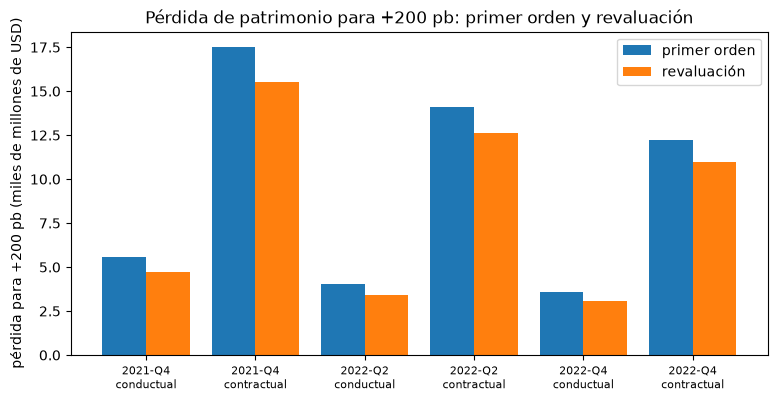

In [4]:
# Pérdida desde la brecha de duración y la revaluación completa, y pérdida de NII desde la brecha y la proyección
approx = {}
print("depósitos | patrimonio: primer orden | patrimonio: revaluación | NII: brecha | NII: dinámico")
for q, d in docs.items():
    o = d["outputs"]
    dynamic_up = next(s["delta_vs_base"] for s in o["dynamic_nii"]["scenarios"] if s["scenario"] == "parallel-up")
    shocked = shocks.apply_floor(book[q]["r0"], np.full(19, 200.0), 0.0)
    for treatment in ("behavioural", "contractual"):
        a, l = book[q]["flows"][treatment]
        dg = eve_nii.duration_gap(a, l, book[q]["r0"], MID)
        full = eve_nii.delta_eve(a - l, a - l, book[q]["r0"], shocked, MID)
        gap_nii = 2.0 * eve_nii.delta_nii_gap(eve_nii.repricing_gap(a, l), MID, 100.0)
        approx[(q, treatment)] = (-2.0 * dg.equity_change_100bp_up, full)
        dyn = f"{dynamic_up:12,.0f}" if treatment == "behavioural" else "-"
        print(f"{q} {NAME[treatment]:12s} {approx[(q, treatment)][0]:12,.0f} {full:12,.0f} {gap_nii:10,.0f} {dyn}")
fig, ax = plt.subplots(figsize=(9, 4.2))
keys = list(approx)
ax.bar(np.arange(len(keys)) - 0.2, [approx[k][0] / 1e6 for k in keys], 0.4, label="primer orden")
ax.bar(np.arange(len(keys)) + 0.2, [approx[k][1] / 1e6 for k in keys], 0.4, label="revaluación")
ax.set_xticks(range(len(keys)), [f"{q}\n{NAME[t]}" for q, t in keys], fontsize=8)
ax.set_ylabel("pérdida para +200 pb (miles de millones de USD)")
ax.set_title("Pérdida de patrimonio para +200 pb: primer orden y revaluación")
ax.legend()
plt.show()

La pérdida de primer orden sobrestima la revaluación en cerca de 18 por ciento con los depósitos conductuales en todas las fechas (5.549.598 frente a 4.696.651 en 2021-Q4, 4.016.983 frente a 3.389.057 en 2022-Q2, 3.602.676 frente a 3.056.308 en 2022-Q4) y en 11 a 13 por ciento con los contractuales: el orden de magnitud correcto y el signo correcto, con un sesgo estable entre las fechas, que es lo que muestra la figura. La tabla impresa arriba lleva el NII, donde las aproximaciones no coinciden ni en el signo: la brecha de reprecio dice que un choque de +200 pb cuesta 455.806, 398.114 y 349.294, y la proyección dinámica dice que gana 1.138.367, 1.058.869 y 483.444. La diferencia es el traspaso de los depósitos: la brecha reprecia los depósitos no estables uno a uno, la proyección les da un beta entre 0,02 y 0,26. El signo de la sensibilidad del NII de este banco es una afirmación sobre su beta de depósitos.

### Comparación 3: tres tratamientos de los depósitos

El estándar ubica la parte estable de los depósitos a la vista bajo topes; la práctica interna replica el depósito con una cartera de tramos rodantes y usa su plazo promedio. La celda toma el segmento mayorista, el más grande, y lo ubica de tres maneras con `nmd_split` del motor: todo depósito a un día (la lectura contractual), los topes del estándar (la lectura conductual versionada, 50 por ciento estable a 4 años), y la lectura **replicante**, donde todo el saldo está en el plazo promedio del ajuste replicante versionado de la fecha (proporción 100 por ciento, sin tope, `enforce_caps=False`). El resto del balance se mantiene como está versionado. Para cada tratamiento imprime el EVE y la pérdida bajo el choque paralelo de +200 pb con piso en cero, de modo que solo cambia el tratamiento de los depósitos mayoristas. Es un qué pasaría sobre los flujos versionados (omite de los flujos con choque el rescate anticipado de depósitos a plazo, una partida de 322.000), no un número versionado.

In [5]:
# Ubicar los depósitos mayoristas de tres maneras y calcular el EVE y la pérdida bajo +200 pb con piso en cero
deposit = {}
print("tratamiento | plazo promedio (a) | EVE | pérdida para +200 pb | proporción del Tier 1")
for q, d in docs.items():
    o = d["outputs"]
    segment = next(s for s in o["nmd_segments"] if s["category"] == "wholesale")
    model = next(m for m in fit["nmd_models"] if m["valuation_date"] == o["valuation_date"])
    balance = segment["balance"]
    request = (segment["requested_core_share"], segment["requested_core_maturity_years"])
    standard = slotting.nmd_split(balance, "wholesale", *request)
    a, l = book[q]["flows"]["behavioural"]
    others = (a - l) + standard.flows
    wam_fit = model["weighted_average_maturity_years"]
    replicating = slotting.nmd_split(balance, "wholesale", 1.0, wam_fit, enforce_caps=False)
    treatments = {"contractual": slotting.nmd_split(balance, "wholesale", 0.0, 0.0), "topes del estándar": standard}
    treatments["cartera replicante"] = replicating
    shocked = shocks.apply_floor(book[q]["r0"], np.full(19, 200.0), 0.0)
    for name, split in treatments.items():
        net = others - split.flows
        value = eve_nii.eve(net, book[q]["r0"], MID)
        loss = eve_nii.delta_eve(net, net, book[q]["r0"], shocked, MID)
        wam = float((split.flows * MID).sum() / split.flows.sum())
        deposit[(q, name)] = (value, loss)
        print(f"{q} {name:24s} {wam:8.4f} {value:14,.0f} {loss:14,.0f} {loss / book[q]['tier1']:8.4f}")

tratamiento | plazo promedio (a) | EVE | pérdida para +200 pb | proporción del Tier 1
2021-Q4 contractual                0.0028      4,868,904     11,542,342   0.7894
2021-Q4 topes del estándar         2.0014      8,982,670      4,696,651   0.3212
2021-Q4 cartera replicante         4.7595     15,459,666     -4,423,382  -0.3025
2022-Q2 contractual                0.0028     -3,373,439      9,694,356   0.5930
2022-Q2 topes del estándar         2.0014      7,036,780      3,389,057   0.2073
2022-Q2 cartera replicante         4.2049     18,465,257     -3,460,623  -0.2117
2022-Q4 contractual                0.0028     -7,338,446      8,571,364   0.5043
2022-Q4 topes del estándar         2.0014      5,257,968      3,056,308   0.1798
2022-Q4 cartera replicante         5.0000     22,947,683     -4,607,251  -0.2711


La celda siguiente dibuja la pérdida bajo +200 pb para los tres tratamientos en las tres fechas.

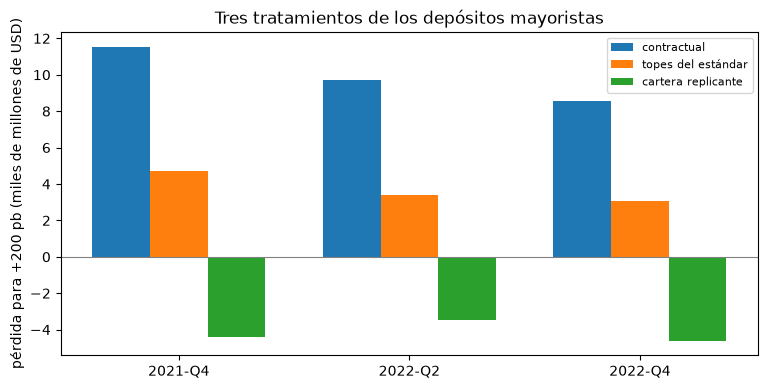

In [6]:
# Dibujar la pérdida bajo +200 pb para los tres tratamientos de depósitos en las tres fechas
treat = list(dict.fromkeys(n for _, n in deposit))
fig, ax = plt.subplots(figsize=(9, 4.2))
for k, name in enumerate(treat):
    ax.bar(np.arange(3) + k * 0.25 - 0.25, [deposit[(q, name)][1] / 1e6 for q in docs], 0.25, label=name)
ax.axhline(0, color="grey", linewidth=0.8)
ax.set_xticks(range(3), list(docs))
ax.set_ylabel("pérdida para +200 pb (miles de millones de USD)")
ax.set_title("Tres tratamientos de los depósitos mayoristas")
ax.legend(fontsize=8)
plt.show()

En 2022-Q2 los depósitos mayoristas, 185 mil millones del balance, dan tres bancos distintos. Ubicados a un día, el EVE es -3.373.439 y la pérdida a +200 pb 9.694.356, 59 por ciento del Tier 1. Con los topes del estándar, el EVE es 7.036.780 y la pérdida 3.389.057, 21 por ciento. Con la cartera replicante todo el saldo está a 4,2 años, el EVE es 18.465.257 y el choque de +200 pb es una ganancia de 3.460.623, la barra bajo cero. El signo se invierte igual en las tres fechas, con plazos ajustados de 4,76, 4,20 y 5,00 años. Es la palanca que describe la revisión del banco quebrado: una duración larga de los depósitos, ajustada con el historial del propio banco, puede hacer desaparecer una pérdida, y los topes del estándar son lo que lo impide. El notebook 05 mostró que los pesos detrás de esos plazos no son estables. La figura es un qué pasaría sobre los flujos versionados, no un número versionado.

### Comparación 4: las calibraciones de 2016 y de 2024

La recalibración de los tamaños de choque (d578, vigente desde 2026-01-01) es el único cambio del estándar en el período. Los escenarios versionados guardan los seis choques bajo ambas tablas con los flujos conductuales con tope, y el motor guarda ambas tablas de tamaños. La celda toma los tamaños del USD de cada calibración, arma las seis curvas con choque de los flujos conductuales con piso en cero, llama a `eve_risk_measure` y a la prueba de valores atípicos, e imprime, para cada fecha, la medida, el peor choque y la razón al Tier 1; dibuja la medida bajo ambas.

calibración | tamaños (pb) | medida | peor choque | razón
2021-Q4 2016 200/300/150    4,696,651 paralelo al alza     0.3212
2021-Q4 2024 200/300/225    4,980,555 empinamiento         0.3406
2022-Q2 2016 200/300/150    3,389,057 paralelo al alza     0.2073
2022-Q2 2024 200/300/225    3,418,160 empinamiento         0.2091
2022-Q4 2016 200/300/150    3,056,308 paralelo al alza     0.1798
2022-Q4 2024 200/300/225    3,072,112 empinamiento         0.1808


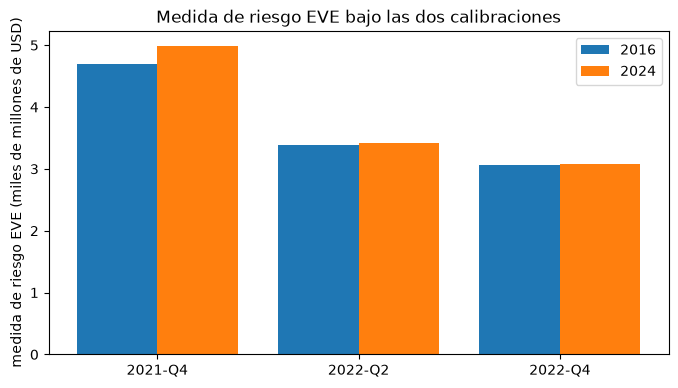

In [7]:
# La medida de riesgo EVE bajo las calibraciones de 2016 y de 2024, desde las seis curvas con choque
cal_measure = {}
print("calibración | tamaños (pb) | medida | peor choque | razón")
for q in docs:
    a, l = book[q]["flows"]["behavioural"]
    net, r0 = a - l, book[q]["r0"]
    for cal in ("2016", "2024"):
        z = shocks.shock_size("USD", cal)
        deltas = []
        for s in shocks.SHOCKS:
            shape = shocks.shock_curve(s, z.parallel_bp, z.short_bp, z.long_bp, MID)
            deltas.append(eve_nii.delta_eve(net, net, r0, shocks.apply_floor(r0, shape, 0.0), MID))
        measure = eve_nii.eve_risk_measure(np.array(deltas).reshape(6, 1))
        worst = shocks.SHOCKS[int(np.argmax(deltas))]
        ratio = eve_nii.outlier_test(measure, book[q]["tier1"]).ratio
        cal_measure[(q, cal)] = measure
        sizes = f"{z.parallel_bp:.0f}/{z.short_bp:.0f}/{z.long_bp:.0f}"
        print(f"{q} {cal} {sizes} {measure:12,.0f} {NAME[worst]:20s} {ratio:.4f}")
fig, ax = plt.subplots(figsize=(8, 4.2))
for k, cal in enumerate(("2016", "2024")):
    ax.bar(np.arange(3) + k * 0.4 - 0.2, [cal_measure[(q, cal)] / 1e6 for q in docs], 0.4, label=cal)
ax.set_xticks(range(3), list(docs))
ax.set_ylabel("medida de riesgo EVE (miles de millones de USD)")
ax.set_title("Medida de riesgo EVE bajo las dos calibraciones")
ax.legend()
plt.show()

Con los tamaños de 2016 el peor choque es el paralelo al alza en las tres fechas; con los de 2024, cuyo tamaño largo es 225 pb en vez de 150 pb, es el empinamiento. La medida sube 6,0 por ciento en 2021-Q4 (4.696.651 a 4.980.555), 0,9 por ciento en 2022-Q2 y 0,5 por ciento en 2022-Q4, como muestran las barras, y la razón con los tamaños de 2024, 0,3406, 0,2091 y 0,1808, sigue sobre la línea de 0,15 en todas las fechas: la recalibración cambia la forma que más daña, no el veredicto de este caso. Las cifras se recalculan desde los flujos conductuales con piso en cero y difieren de la medida versionada del proceso en unos cientos, por dejar fuera el rescate anticipado de depósitos a plazo. La imagen son los tamaños de una moneda sobre un banco.

## Resultados

**Respuesta:** ninguna elección de las cuatro cambia el veredicto de que el banco está sobre la línea de 15 por ciento, pero el tratamiento de los depósitos cambia el signo de la pérdida. En 2022-Q2 la pérdida a +200 pb es 9.694.356 con todo depósito a un día, 3.389.057 con los topes del estándar y una ganancia de 3.460.623 con la cartera replicante; la familia de curvas mueve el EVE entre 6.647.794 y 7.360.948 en torno a los 7.036.780 de la curva del proceso; la brecha y la proyección dinámica discrepan en el signo sobre el NII (un costo de 398.114 frente a una ganancia de 1.058.869); y la recalibración de 2024 sube la medida en 6,0 por ciento en 2021-Q4 y hace del empinamiento el peor choque, con una razón de 0,2091 en 2022-Q2.

- **Lo que cubre el motor.** De las familias que encontró la investigación, el motor implementa los ajustes de curva, Hull-White de un factor, la cartera replicante estática, el beta de depósitos y un logit de prepago, y no implementa Vasicek, otro esquema de interpolación, los modelos de depósitos de derechos contingentes ni de tres factores, ni la programación estocástica. Un validador que los necesite debe traer un desafiante de afuera; la investigación no encontró un motor ALM de código abierto maduro que traer, un hallazgo que queda sin verificar más allá de la búsqueda del dossier.
- **La familia de curvas.** Sobre los mismos 12 rendimientos observados las cuatro maneras de obtener las 19 tasas cero mueven el EVE entre -388.987 y +324.168 en 2022-Q2, como máximo 2,4 por ciento del Tier 1 pero hasta 10 por ciento del propio EVE, con una mayor brecha de 52,3 pb en una sola tasa.
- **Las aproximaciones de primer orden.** Para +200 pb la brecha de duración sobrestima la pérdida de la revaluación completa en cerca de 18 por ciento con los depósitos conductuales y en 11 a 13 por ciento con los contractuales: el orden de magnitud y el signo correctos, con un sesgo estable. Las aproximaciones del NII no coinciden ni en el signo: la brecha dice que +200 pb cuesta 455.806, 398.114 y 349.294, y la proyección dinámica dice que gana 1.138.367, 1.058.869 y 483.444, por el traspaso de los depósitos.
- **Los depósitos.** En 2022-Q2 el EVE es -3.373.439 a un día, 7.036.780 con los topes y 18.465.257 con la cartera replicante. El signo de la pérdida a +200 pb se invierte en las tres fechas (plazos promedio de 4,76, 4,20 y 5,00 años). Es la palanca que describe la revisión del banco quebrado; los topes del estándar la detienen, y el notebook 05 mostró que los pesos detrás de esos plazos no son estables.
- **La recalibración de 2024.** Con los tamaños de 2016 el peor choque es el paralelo al alza en las tres fechas; con los de 2024, cuyo tamaño largo es 225 pb en vez de 150 pb, es el empinamiento. La medida sube de 4.696.651 a 4.980.555 en 2021-Q4, y la razón sigue sobre 0,15 en todos los casos.
- **Lo que el notebook no muestra.** Que alguna de las alternativas sea mejor que las elecciones del proceso: no hay una verdad contra la cual comparar para un banco cuyo comportamiento es sintético. El notebook muestra el tamaño de las elecciones, para que un validador sepa dónde mirar primero: el tratamiento de los depósitos, luego el beta, luego la curva.

## Resumen

- El motor implementa una parte del estado del arte: las familias de curvas, Hull-White de un factor, la cartera replicante estática, el beta de depósitos y un logit de prepago; no implementa Vasicek, otros esquemas de interpolación, los modelos de depósitos por derechos contingentes ni de tres factores, ni la programación estocástica.
- La familia de curvas mueve el EVE de los mismos flujos en una proporción pequeña del Tier 1; el tratamiento de los depósitos mueve la pérdida en un múltiplo.
- Las aproximaciones de primer orden dan el orden de magnitud del cambio del patrimonio, pero la brecha y el NII dinámico pueden discrepar incluso en el signo, porque tratan de forma distinta el traspaso de los depósitos.
- La recalibración de 2024 cambia los tamaños del extremo largo y con ello el peor choque del caso, del paralelo al alza al empinamiento, sin cambiar el veredicto de la prueba de valores atípicos.
- No se encontró un motor de código abierto maduro que desafíe los resultados; es un hallazgo de la búsqueda del dossier, no verificado más allá de ella.

**Qué probar a continuación.** Reemplaza los +200 pb de la comparación 3 por el empinamiento del notebook 02 y mira si se mantiene el orden de los tres tratamientos de depósitos. Después sigue con el notebook 08, los componentes más allá del estado del arte.

## Referencias

- Nelson, C. R. y Siegel, A. F. (1987), Parsimonious modeling of yield curves, Journal of Business 60(4). https://doi.org/10.1086/296409
- Svensson, L. E. O. (1994), Estimating and interpreting forward interest rates: Sweden 1992-1994, NBER Working Paper 4871. https://doi.org/10.3386/w4871
- Diebold, F. X. y Li, C. (2006), Forecasting the term structure of government bond yields, Journal of Econometrics 130(2). https://doi.org/10.1016/j.jeconom.2005.03.005
- Hagan, P. S. y West, G. (2006), Interpolation methods for curve construction, Applied Mathematical Finance 13(2). https://doi.org/10.1080/13504860500396032
- Vasicek, O. (1977), An equilibrium characterization of the term structure, Journal of Financial Economics 5(2). https://doi.org/10.1016/0304-405X(77)90016-2
- Hull, J. y White, A. (1990), Pricing interest-rate-derivative securities, Review of Financial Studies 3(4). https://doi.org/10.1093/rfs/3.4.573
- Jarrow, R. y van Deventer, D. (1998), The arbitrage-free valuation and hedging of demand deposits and credit card loans, Journal of Banking and Finance 22(3). https://doi.org/10.1016/S0378-4266(97)00058-7
- Kalkbrener, M. y Willing, J. (2004), Risk management of non-maturing liabilities, Journal of Banking and Finance 28(7). https://doi.org/10.1016/S0378-4266(03)00131-6
- Frauendorfer, K. y Schurle, M. (2003), Multistage stochastic programming: optimal reinvestment of non-maturing liabilities, European Journal of Operational Research 151(3). https://doi.org/10.1016/S0377-2217(02)00626-4
- Drechsler, I., Savov, A. y Schnabl, P. (2021), Banking on deposits: maturity transformation without interest rate risk, Journal of Finance 76(3). https://doi.org/10.1111/jofi.13013
- Stanton, R. (1995), Rational prepayment and the valuation of mortgage-backed securities, Review of Financial Studies 8(3). https://doi.org/10.1093/rfs/8.3.677
- Schwartz, E. S. y Torous, W. N. (1989), Prepayment and the valuation of mortgage-backed securities, Journal of Finance 44(2). https://doi.org/10.1111/j.1540-6261.1989.tb05062.x
- Deng, Y., Quigley, J. M. y Van Order, R. (2000), Mortgage terminations, heterogeneity and the exercise of mortgage options, Econometrica 68(2). https://doi.org/10.1111/1468-0262.00110
- Fuster, A., Lucca, D. y Vickery, J. (2022), Mortgage-backed securities, FRBNY Staff Report 1001. https://www.newyorkfed.org/medialibrary/media/research/staff_reports/sr1001.pdf
- BCBS, Standards: Interest rate risk in the banking book, SRP31. https://www.bis.org/basel_framework/chapter/SRP/31.htm
- BCBS (2016), d368, Standards: Interest rate risk in the banking book. https://www.bis.org/bcbs/publ/d368.htm
- BCBS (2024), d578, Recalibration of shocks for interest rate risk in the banking book. https://www.bis.org/publications/202407-standards-recalibration-shocks-interest-rate-risk-banking-book.pdf
- Board of Governors of the Federal Reserve System (2023), Review of the Federal Reserve's Supervision and Regulation of Silicon Valley Bank. https://www.federalreserve.gov/publications/files/svb-review-20230428.pdf
- Dossiers 01, 03 y 05 de la investigación de Contraste (marco de Basilea; Chile; modelos de mercado, ALM y liquidez).